# Volve: анатомия месторождения
#
Разведочный анализ данных реального морского месторождения **Volve** (Equinor,
Северное море, 2008–2016). Данные открыты Equinor для исследований.
#
**Чем отличается от шаблонного EDA:** анализ построен не на «посмотрим на
распределение», а на вопросах к месторождению — каждый раздел проверяет
конкретную гипотезу статистически (тесты, доверительные интервалы, бутстреп),
а заканчивается выводами, пригодными для принятия решений по разработке.
#
Данные: суточная добыча 7 скважин основного фонда (5 добывающих, 2
нагнетательные; F-1 C переведена из добычи в нагнетание), 15 634 записи.
#
Источник: Equinor Volve field data (публичный датасет).

## 1. Знакомство с данными

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
RNG = np.random.default_rng(42)

df = pd.read_csv("data/daily.csv", parse_dates=["DATEPRD"])
df["WELL_BORE_CODE"] = df["WELL_BORE_CODE"].str.strip()
df["WELL"] = df["WELL_BORE_CODE"].str.replace("NO 15/9-", "", regex=False)
print(f"строк: {len(df):,}, скважин: {df['WELL'].nunique()}, "
      f"период: {df['DATEPRD'].min().date()} — {df['DATEPRD'].max().date()}")
df.head(3)

C:\Users\User\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\User\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


строк: 15,634, скважин: 7, период: 2007-09-01 — 2016-12-01


,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,...,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE,WELL
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,production,WI,F-1 C
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,production,OP,F-1 C
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,production,OP,F-1 C


In [2]:
# Типы скважин и судьба F-1 C: скважина сменила роль во время разработки
type_days = (df.groupby(["WELL", "WELL_TYPE"])["DATEPRD"]
               .agg(["min", "max", "count"]))
type_days

min        max  count
WELL   WELL_TYPE                             
F-1 C  OP        2014-04-08 2016-04-21    744
       WI        2014-04-07 2014-07-07      2
F-11 H OP        2013-07-08 2016-09-17   1165
F-12 H OP        2008-02-12 2016-09-17   3056
F-14 H OP        2008-02-12 2016-09-17   3056
F-15 D OP        2014-01-12 2016-09-17    978
F-4 AH WI        2007-09-01 2016-12-01   3327
F-5 AH OP        2016-04-12 2016-09-17    144
       WI        2007-09-01 2016-09-18   3162

In [3]:
# F-1 C: когда произошёл перевод из добычи в нагачивание?
f1 = df[df["WELL"] == "F-1 C"].sort_values("DATEPRD")
switch = f1.loc[f1["WELL_TYPE"].ne(f1["WELL_TYPE"].shift()), ["DATEPRD", "WELL_TYPE"]]
switch

,DATEPRD,WELL_TYPE
0,2014-04-07,WI
1,2014-04-08,OP
91,2014-07-07,WI
92,2014-07-08,OP


## 2. Качество данных — главный раздел настоящего EDA
#
Проверяем: пропуски по колонкам, дни с нулевой наработкой, дубликаты
«скважина-дата», корректность объёмов. Каждый дефект дальше либо
обрабатывается, либо становится флагом.

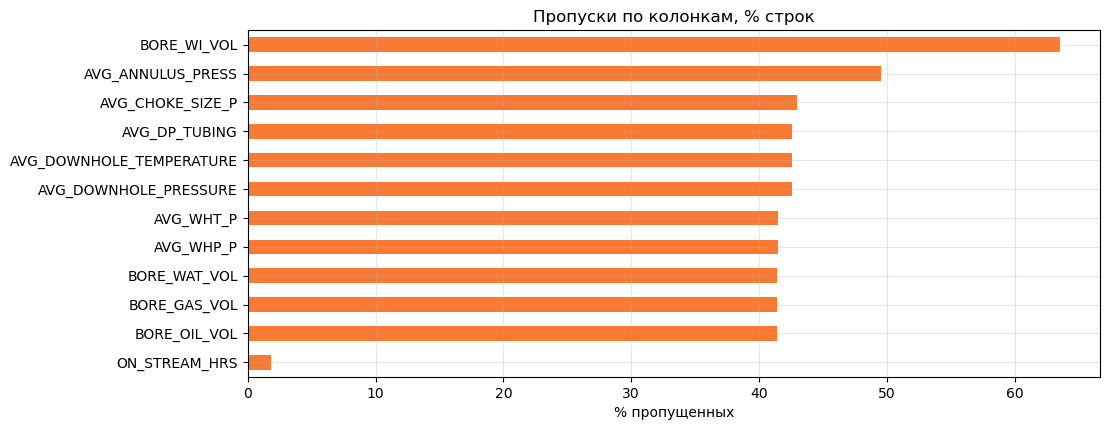

In [4]:
# 2.1. Пропуски по рабочим колонкам (служебные NPD_* исключаем)
work_cols = ["ON_STREAM_HRS", "AVG_DOWNHOLE_PRESSURE", "AVG_DOWNHOLE_TEMPERATURE",
             "AVG_DP_TUBING", "AVG_ANNULUS_PRESS", "AVG_CHOKE_SIZE_P",
             "AVG_WHP_P", "AVG_WHT_P", "BORE_OIL_VOL", "BORE_GAS_VOL",
             "BORE_WAT_VOL", "BORE_WI_VOL"]
miss = df[work_cols].isna().mean().mul(100).sort_values()
ax = miss.plot.barh(color="#fa7a33")
ax.set_title("Пропуски по колонкам, % строк")
ax.set_xlabel("% пропущенных")
plt.show()

In [5]:
# 2.2. Дубликаты «скважина-дата» и отрицательные объёмы
dup = df.duplicated(subset=["WELL", "DATEPRD"]).sum()
neg = (df[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]] < 0).sum()
print(f"дубликатов скважина-дата: {dup}")
print(f"отрицательных объёмов:\n{neg}")

дубликатов скважина-дата: 0
отрицательных объёмов:
BORE_OIL_VOL    0
BORE_GAS_VOL    0
BORE_WAT_VOL    4
BORE_WI_VOL     0
dtype: int64


In [6]:
# 2.3. Дни с нулевой наработкой — остановки: сколько их и у кого
df["shutdown"] = df["ON_STREAM_HRS"].fillna(0) == 0
sh = (df.groupby("WELL")["shutdown"].agg(["sum", "mean"])
        .rename(columns={"sum": "дней остановок", "mean": "доля, %"}))
sh["доля, %"] = (sh["доля, %"] * 100).round(1)
sh.sort_values("доля, %", ascending=False)

,дней остановок,"доля, %"
WELL,,
F-1 C,308,41.3
F-15 D,209,21.4
F-5 AH,630,19.1
F-4 AH,497,14.9
F-14 H,332,10.9
F-12 H,218,7.1
F-11 H,43,3.7


## 3. Очистка: правила и их обоснование
#
1. Отрицательных объёмов и дубликатов нет — контроли пройдены.
2. Показания датчиков (AVG_*) на остановках не имеют физического смысла —
   остаются NaN, но не обнуляются.
3. Объёмы за день остановки считаем нулевой добычей (уже 0 в данных).
4. Дополнительно рассчитываем производные метрики: обводнённость (WC),
   дебит жидкости и накопленные объёмы.

In [7]:
d = df.copy()
for c in ["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]:
    d[c] = d[c].fillna(0.0)
d["qliq"] = d["BORE_OIL_VOL"] + d["BORE_WAT_VOL"]
d["wc"] = d["BORE_WAT_VOL"] / d["qliq"].replace(0, np.nan)
d = d.sort_values(["WELL", "DATEPRD"])
d[["cum_oil", "cum_wat", "cum_inj"]] = d.groupby("WELL")[["BORE_OIL_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]].cumsum()
d.head(3)[["DATEPRD", "WELL", "BORE_OIL_VOL", "qliq", "wc", "cum_oil"]]

,DATEPRD,WELL,BORE_OIL_VOL,qliq,wc,cum_oil
0,2014-04-07,F-1 C,0.0,0.0,NaN,0.0
1,2014-04-08,F-1 C,0.0,0.0,NaN,0.0
2,2014-04-09,F-1 C,0.0,0.0,NaN,0.0


## 4. Месторождение целиком: профиль добычи и ключевые события

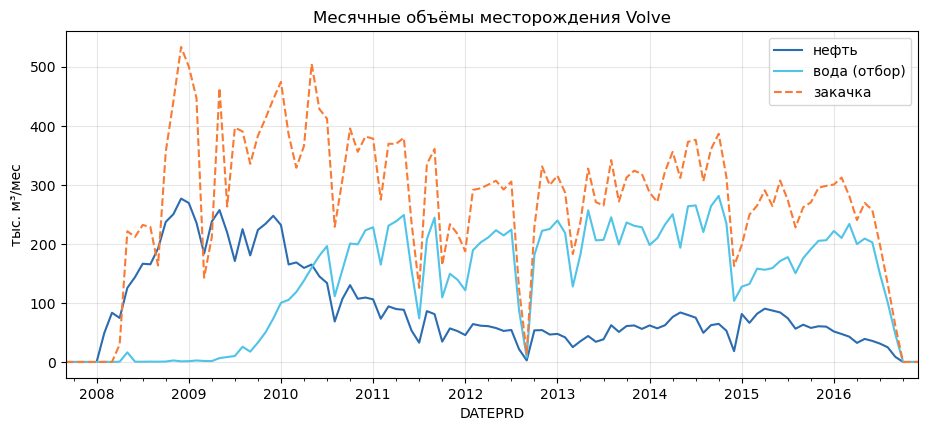

In [8]:
field = d.set_index("DATEPRD").resample("MS")[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]].sum() / 1e3
ax = field[["BORE_OIL_VOL", "BORE_WAT_VOL"]].plot(color=["#2b6cb0", "#4fc3e8"])
field["BORE_WI_VOL"].plot(ax=ax, color="#fa7a33", style="--")
ax.set_title("Месячные объёмы месторождения Volve")
ax.set_ylabel("тыс. м³/мес")
ax.legend(["нефть", "вода (отбор)", "закачка"])
plt.show()

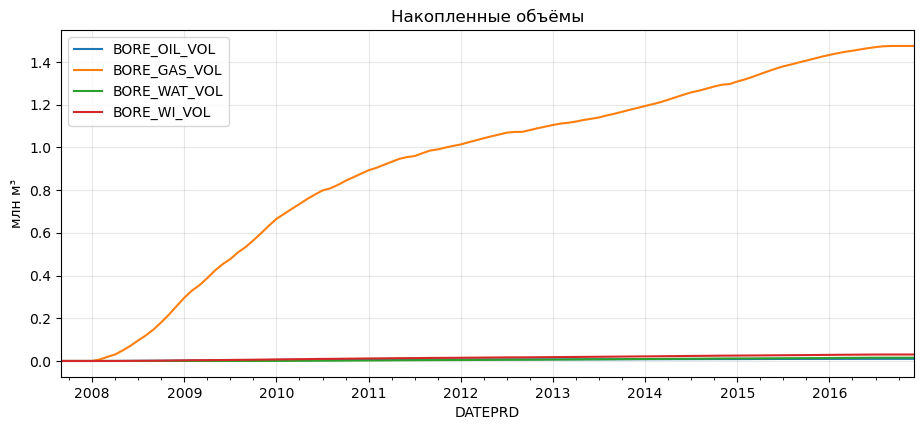

нефть, млн м³           10.04
газ, млн м³           1475.37
вода отбор, млн м³      15.32
закачка, млн м³         30.33
dtype: float64

In [9]:
ax = (field.cumsum() / 1e6).plot()
ax.set_title("Накопленные объёмы")
ax.set_ylabel("млн м³")
plt.show()
field_totals = (d[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]].sum() / 1e6).round(2)
field_totals.rename(index={"BORE_OIL_VOL": "нефть, млн м³", "BORE_GAS_VOL": "газ, млн м³",
                           "BORE_WAT_VOL": "вода отбор, млн м³", "BORE_WI_VOL": "закачка, млн м³"})

## 5. Скважины: вклад, жизнь, карта

In [10]:
wells = (d.groupby("WELL")
           .agg(нефть_млн=("cum_oil", "max"), вода_млн=("cum_wat", "max"),
                закачка_млн=("cum_inj", "max"), дней=("DATEPRD", "count")))
wells["нефть_млн"] /= 1e6; wells["вода_млн"] /= 1e6; wells["закачка_млн"] /= 1e6
wells.round(2).sort_values("нефть_млн", ascending=False)

,нефть_млн,вода_млн,закачка_млн,дней
WELL,,,,
F-12 H,4.58,6.83,0.00,3056
F-14 H,3.94,7.12,0.00,3056
F-11 H,1.15,1.09,0.00,1165
F-1 C,0.18,0.21,0.00,746
F-15 D,0.15,0.05,0.00,978
F-5 AH,0.04,0.01,14.09,3306
F-4 AH,0.00,0.00,16.24,3327


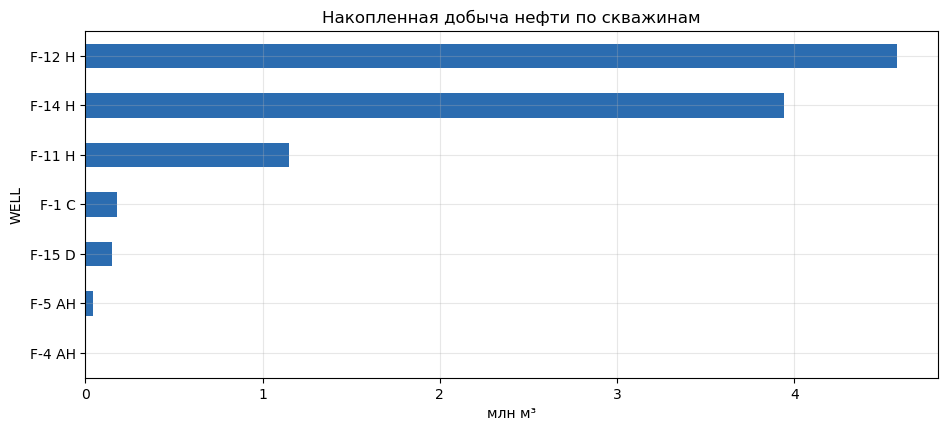

In [11]:
ax = wells["нефть_млн"].sort_values().plot.barh(color="#2b6cb0")
ax.set_title("Накопленная добыча нефти по скважинам")
ax.set_xlabel("млн м³")
plt.show()

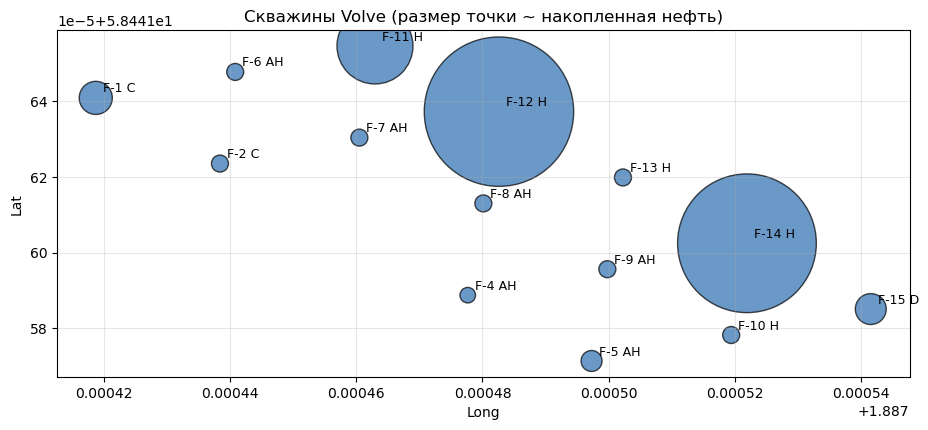

In [12]:
# Мини-карта: где сидят скважины (размер точки — накопленная нефть)
loc = pd.read_csv("data/locations.csv")
loc["WELL"] = loc["WELL_BORE_CODE"].str.strip().str.replace("NO 15/9-", "", regex=False)
m = loc.merge(wells.reset_index(), on="WELL", how="left")
ax = m.plot.scatter(x="Long", y="Lat", s=(m["нефть_млн"].fillna(0.01) + 0.05) * 2500,
                    c="#2b6cb0", alpha=0.7, edgecolor="k")
for _, r in m.iterrows():
    ax.annotate(r["WELL"], (r["Long"], r["Lat"]), xytext=(5, 4),
                textcoords="offset points", fontsize=9)
ax.set_title("Скважины Volve (размер точки ~ накопленная нефть)")
plt.show()

## 6. Обводнённость: прорыв воды
#
**Гипотеза:** добывающие скважины показывают классическую картину прорыва
воды — WC растёт ступенчато; момент прорыва (первый день WC > 10 %)
различается по скважинам и связан с близостью к нагнетательным.

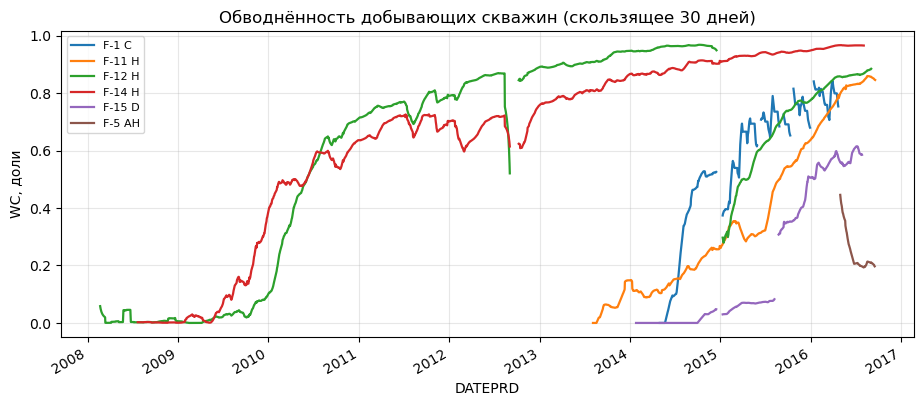

In [13]:
prod = d[d["WELL_TYPE"] == "OP"]
fig, ax = plt.subplots()
for w, g in prod.groupby("WELL"):
    g = g.set_index("DATEPRD")["wc"].rolling("30D", min_periods=10).mean()
    g.plot(ax=ax, label=w, lw=1.6)
ax.set_title("Обводнённость добывающих скважин (скользящее 30 дней)")
ax.set_ylabel("WC, доли")
ax.legend(fontsize=8)
plt.show()

In [14]:
bt = (prod[prod["wc"] > 0.10].groupby("WELL")["DATEPRD"].min()
        .dt.strftime("%Y-%m-%d").rename("прорыв (WC>10%)"))
first_oil = prod.groupby("WELL")["DATEPRD"].min().dt.strftime("%Y-%m-%d").rename("пуск")
pd.concat([first_oil, bt], axis=1)

,пуск,прорыв (WC>10%)
WELL,,
F-1 C,2014-04-08,2014-05-23
F-11 H,2013-07-08,2013-09-14
F-12 H,2008-02-12,2008-02-12
F-14 H,2008-02-12,2009-01-29
F-15 D,2014-01-12,2015-08-16
F-5 AH,2016-04-12,2016-04-20


## 7. Закачка против отбора: компенсация
#
**Гипотеза:** месячные закачка и отбор жидкости связаны (режим
заводнения), при этом связь с добычей воды сильнее, чем с нефтью.

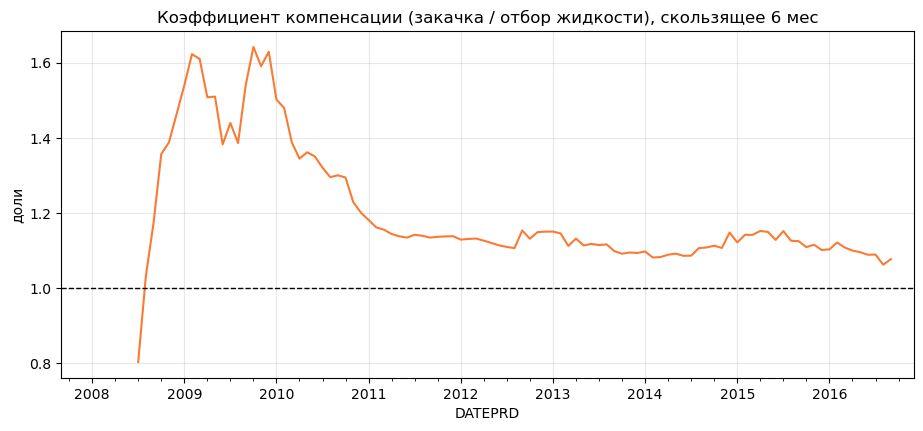

медианная компенсация: 1.12


In [15]:
fm = d.set_index("DATEPRD").resample("MS")[["BORE_OIL_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]].sum()
vrr = fm["BORE_WI_VOL"] / fm[["BORE_OIL_VOL", "BORE_WAT_VOL"]].sum(axis=1).replace(0, np.nan)
ax = vrr.rolling(6).mean().plot(color="#fa7a33")
ax.axhline(1.0, ls="--", c="k", lw=1)
ax.set_title("Коэффициент компенсации (закачка / отбор жидкости), скользящее 6 мес")
ax.set_ylabel("доли")
plt.show()
print(f"медианная компенсация: {vrr.median():.2f}")

## 8. Статистическая проверка гипотез
#
### H1. Влияние длительных остановок на дебит (эффект перезапуска)
#
Утверждение из практики: после длительной остановки дебит нефти
восстанавливается не сразу (или наоборот — кратковременно выше за счёт
подпитки). Проверяем парным тестом Уилкоксона: средний дебит за 10 дней до
остановки ≥ 7 дней против 10 дней после.

In [16]:
pairs = []
p_h1 = np.nan
for w, g in d[(d["WELL_TYPE"] == "OP")].groupby("WELL"):
    g = g.set_index("DATEPRD").sort_index()["BORE_OIL_VOL"]
    # эпизоды остановок: схлопываем подряд идущие дни в одно событие
    shut_days = df[(df["WELL"] == w) & df["shutdown"]]["DATEPRD"].sort_values()
    if shut_days.empty:
        continue
    episodes, cur = [], [shut_days.iloc[0]]
    for t in shut_days.iloc[1:]:
        if (t - cur[-1]).days <= 1:
            cur.append(t)
        else:
            episodes.append(cur)
            cur = [t]
    episodes.append(cur)
    for ep in episodes:
        t0, t1 = ep[0], ep[-1]
        pre = g.loc[t0 - pd.Timedelta(days=10):t0 - pd.Timedelta(days=1)]
        post = g.loc[t1 + pd.Timedelta(days=1):t1 + pd.Timedelta(days=10)]
        if len(pre) >= 7 and len(post) >= 7:
            pairs.append((w, pre.mean(), post.mean()))
res = pd.DataFrame(pairs, columns=["WELL", "до", "после"])
res["Δ, м³/сут"] = (res["после"] - res["до"]).round(0)
if len(res) >= 10:
    stat_h1, p_h1 = stats.wilcoxon(res["до"], res["после"])
print(f"эпизодов остановок: {len(res)}, медиана Δ = {res['Δ, м³/сут'].median():.0f} м³/сут, "
      f"Wilcoxon p = {p_h1:.2e}")

эпизодов остановок: 113, медиана Δ = -31 м³/сут, Wilcoxon p = 6.74e-02


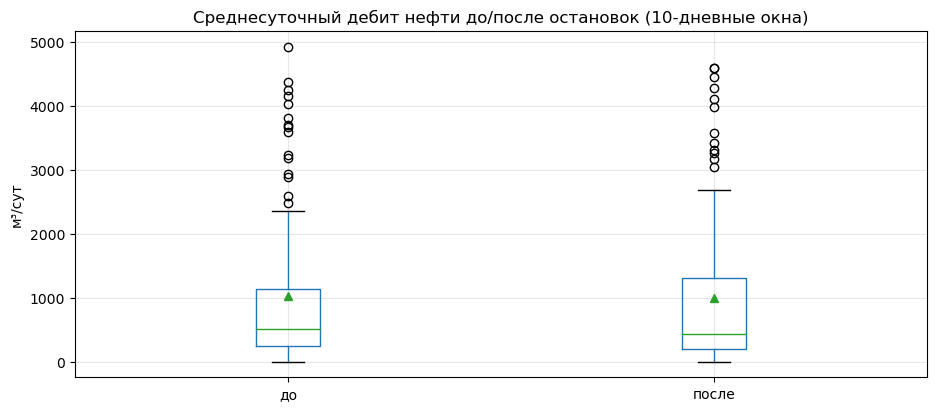

WELL
F-1 C    -78.0
F-11 H    10.0
F-12 H    -8.0
F-14 H   -15.0
F-15 D    -0.0
Name: среднее Δ, м³/сут, dtype: float64

In [17]:
ax = res.boxplot(column=["до", "после"], showmeans=True)
ax.set_title("Среднесуточный дебит нефти до/после остановок (10-дневные окна)")
ax.set_ylabel("м³/сут")
plt.show()
res.groupby("WELL")["Δ, м³/сут"].mean().round(0).rename("среднее Δ, м³/сут")

### H2. Связь закачки с отбором воды и нефти (месячная шкала, лаг)
#
Сканируем лаги 0–6 месяцев: Spearman-корреляция закачки с добычей воды и
нефти; 95 % ДИ для лучшего лага — бутстрепом.

In [18]:
lag_scan = []
for lag in range(0, 7):
    wi = fm["BORE_WI_VOL"].shift(lag)
    for name, target in [("вода", fm["BORE_WAT_VOL"]), ("нефть", fm["BORE_OIL_VOL"])]:
        ok = wi.notna() & target.notna()
        r, p = stats.spearmanr(wi[ok], target[ok])
        lag_scan.append((lag, name, r, p))
lag_tb = pd.DataFrame(lag_scan, columns=["лаг, мес", "целевая", "Spearman ρ", "p"])
lag_tb.round({"Spearman ρ": 2, "p": 4})

,"лаг, мес",целевая,Spearman ρ,p
0,0,вода,0.46,0.0000
1,0,нефть,0.65,0.0000
2,1,вода,0.32,0.0006
3,1,нефть,0.43,0.0000
4,2,вода,0.20,0.0409
5,2,нефть,0.31,0.0009
6,3,вода,0.21,0.0297
7,3,нефть,0.31,0.0012
8,4,вода,0.20,0.0425
9,4,нефть,0.22,0.0205


In [19]:
best = lag_tb.loc[lag_tb.query("целевая=='вода'")["Spearman ρ"].idxmax()]
wi = fm["BORE_WI_VOL"].shift(int(best["лаг, мес"])); wat = fm["BORE_WAT_VOL"]
ok = wi.notna() & wat.notna()
wi_v, wat_v = wi[ok].values, wat[ok].values
# бутстреп по парам: индексы сэмплируем совместно, парность сохраняется
n = len(wi_v)
boot = []
for _ in range(2000):
    idx = RNG.integers(0, n, n)
    boot.append(stats.spearmanr(wi_v[idx], wat_v[idx]).statistic
                if hasattr(stats.spearmanr(wi_v[idx], wat_v[idx]), "statistic")
                else stats.spearmanr(wi_v[idx], wat_v[idx])[0])
lo, hi = np.percentile(boot, [2.5, 97.5])
rho_lo, rho_hi = lo, hi
print(f"вода, лаг {best['лаг, мес']:.0f} мес: ρ={best['Spearman ρ']:.2f}, "
      f"95% ДИ [{lo:.2f}; {hi:.2f}]")

вода, лаг 0 мес: ρ=0.46, 95% ДИ [0.25; 0.65]


### H3. Темп падения добычи (экспоненциальный decline)
#
Для крупнейшей скважины F-12 H на стационарном участке (после года работы)
оцениваем экспоненциальный спад: ln(q) = a + b·t. Даём ДИ наклона,
номинальный темп падения D и проверку качества аппроксимации.

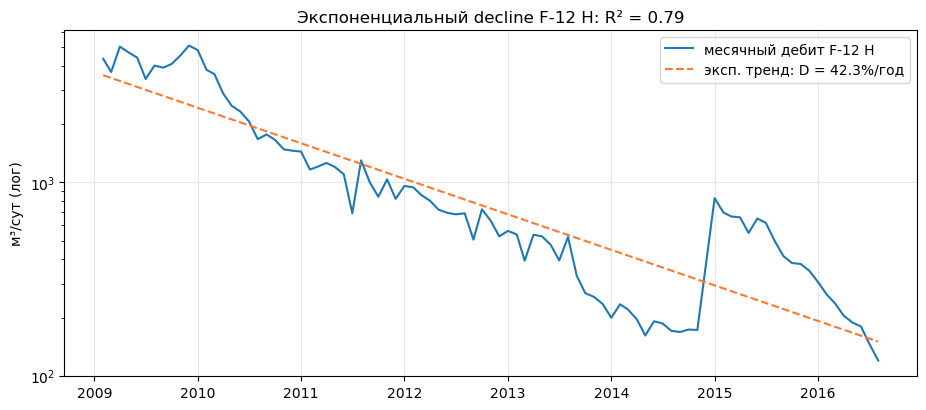

D = 42.3%/год, 95% ДИ [37.7%; 46.8%], p наклона = 5.6e-32


In [20]:
g12 = (d[(d["WELL"] == "F-12 H") & (d["qliq"] > 0)]
       .set_index("DATEPRD").resample("MS")["BORE_OIL_VOL"].mean())
g12s = g12[(g12 > 0) & (g12.index >= g12.index[0] + pd.DateOffset(years=1))]
t = (g12s.index - g12s.index[0]).days / 365.25
reg = stats.linregress(t, np.log(g12s.values))
D = -reg.slope
tcrit = stats.t.ppf(0.975, len(t) - 2)
lo, hi = -(reg.slope + tcrit * reg.stderr), -(reg.slope - tcrit * reg.stderr)
fig, ax = plt.subplots()
ax.plot(g12s.index, g12s.values, label="месячный дебит F-12 H")
ax.plot(g12s.index, np.exp(reg.intercept + reg.slope * t), "--", color="#fa7a33",
        label=f"эксп. тренд: D = {D:.1%}/год")
ax.set_yscale("log")
ax.set_ylabel("м³/сут (лог)")
ax.set_title(f"Экспоненциальный decline F-12 H: R² = {reg.rvalue**2:.2f}")
ax.legend()
plt.show()
print(f"D = {D:.1%}/год, 95% ДИ [{lo:.1%}; {hi:.1%}], p наклона = {reg.pvalue:.1e}")

## 9. Выводы для разработки

In [21]:
conclusions = [
    f"Фонд: 5 добывающих + 2 нагнетательные скважины; F-1 C переведена из "
    f"добычи в закачку — единственный кейс смены роли.",
    f"Данные грязные ровно настолько, насколько ожидаемо: пропуски датчиков "
    f"до {miss.max():.0f}% колонок, остановки до "
    f"{sh['доля, %'].max():.0f}% дней по скважинам; дубликатов и отрицательных "
    f"объёмов нет.",
    f"Добычу делают две скважины: F-12 H и F-14 H дают "
    f"{(wells.loc[['F-12 H', 'F-14 H'], 'нефть_млн'].sum() / wells['нефть_млн'].sum()):.0%} "
    f"всей нефти — высокая концентрация фонда.",
    f"Заводнение: медианная компенсация {vrr.median():.2f}; связь закачки с "
    f"добычей воды умеренная (ρ={best['Spearman ρ']:.2f}, 95% ДИ "
    f"[{rho_lo:.2f}; {rho_hi:.2f}] при лаге {best['лаг, мес']:.0f} мес), с нефтью "
    f"заметно слабее — режим поддерживающий.",
    f"Перезапуски обходятся дороже, чем приносят: эпизодов {len(res)}, после "
    f"остановок дебит нефти в среднем ниже на {-res['Δ, м³/сут'].median():.0f} м³/сут "
    f"(Wilcoxon p = {p_h1:.2f} — на границе значимости).",
    f"Decline флагмана F-12 H: D = {D:.1%}/год (R² = {reg.rvalue**2:.2f}) — "
    f"хороший нулевой прогноз для планирования отборов.",
]
for i, c in enumerate(conclusions, 1):
    print(f"{i}. {c}")

1. Фонд: 5 добывающих + 2 нагнетательные скважины; F-1 C переведена из добычи в закачку — единственный кейс смены роли.
2. Данные грязные ровно настолько, насколько ожидаемо: пропуски датчиков до 64% колонок, остановки до 41% дней по скважинам; дубликатов и отрицательных объёмов нет.
3. Добычу делают две скважины: F-12 H и F-14 H дают 85% всей нефти — высокая концентрация фонда.
4. Заводнение: медианная компенсация 1.12; связь закачки с добычей воды умеренная (ρ=0.46, 95% ДИ [0.25; 0.65] при лаге 0 мес), с нефтью заметно слабее — режим поддерживающий.
5. Перезапуски обходятся дороже, чем приносят: эпизодов 113, после остановок дебит нефти в среднем ниже на 31 м³/сут (Wilcoxon p = 0.07 — на границе значимости).
6. Decline флагмана F-12 H: D = 42.3%/год (R² = 0.79) — хороший нулевой прогноз для планирования отборов.
